# Week 1 – ML Fundamentals + Data Preprocessing
**Machine Learning & AI Course – Internship Task**

Contents
1. Assignment 1 – Load a dataset with Pandas and summarise basic stats
2. Assignment 2 – Handle missing data (mean / median imputation)
3. Assignment 3 – Encode categorical variables (LabelEncoder & OneHotEncoder)
4. **Mini Project 1 – Titanic Survival Prediction: Data Cleaning Project**
5. Bonus – Scaling and Train/Test split (Week 1 topics)

**Dataset:** Titanic (Kaggle `train.csv`, 891 passengers, 12 columns)

## 0. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

## Assignment 1 – Load a dataset and summarise basic stats
`.head()`, `.shape`, `.info()` and `.describe()` give a first look at the data.

In [ ]:
df = pd.read_csv("train.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()

NameError: name 'df' is not defined

In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [6]:
print("Survival rate:", round(df['Survived'].mean(), 4))
df.groupby('Sex')['Survived'].mean()

Survival rate: 0.3838


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

**Observations**
- `Age`, `Cabin` and `Embarked` have missing values (see below).
- `Age` and `Fare` are numeric with very different scales, so scaling matters for distance/gradient based models.
- `Sex` and `Embarked` are categorical and must be encoded before modelling.

## Assignment 2 – Handle missing data (mean / median imputation)
First, measure how much is missing.

In [7]:
missing = pd.DataFrame({'missing': df.isnull().sum(),
                        'percent': (df.isnull().mean() * 100).round(2)})
missing[missing.missing > 0]

,missing,percent
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


Compare mean vs. median for `Age`. Age is right-skewed, so the median is more robust.

In [8]:
print("Age mean  :", round(df['Age'].mean(), 2))
print("Age median:", df['Age'].median())
print("Age skew  :", round(df['Age'].skew(), 3))

Age mean  : 29.7
Age median: 28.0
Age skew  : 0.389


In [9]:
# Mean imputation
age_mean = df.copy()
age_mean['Age'] = age_mean['Age'].fillna(age_mean['Age'].mean())

# Median imputation
age_median = df.copy()
age_median['Age'] = age_median['Age'].fillna(age_median['Age'].median())

# Same thing with scikit-learn's SimpleImputer
imp = SimpleImputer(strategy='median')
age_sk = df.copy()
age_sk[['Age']] = imp.fit_transform(age_sk[['Age']])

print("Remaining NaN in Age -> mean:", age_mean['Age'].isnull().sum(),
      "| median:", age_median['Age'].isnull().sum(),
      "| sklearn:", age_sk['Age'].isnull().sum())
print("Std after mean   imputation:", round(age_mean['Age'].std(), 3))
print("Std after median imputation:", round(age_median['Age'].std(), 3))
print("Std original (non-null)    :", round(df['Age'].std(), 3))

Remaining NaN in Age -> mean: 0 | median: 0 | sklearn: 0
Std after mean   imputation: 13.002
Std after median imputation: 13.02
Std original (non-null)    : 14.526


**Categorical columns** cannot use mean/median – use the **mode** (most frequent value).
`Cabin` is ~77% missing, so imputing would be mostly invented data; it is dropped in the mini project.

In [10]:
print(df['Embarked'].value_counts(dropna=False))
print("Mode:", df['Embarked'].mode()[0])

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64
Mode: S


## Assignment 3 – Encode categorical variables
- **LabelEncoder** – maps each category to an integer (fine for binary columns like `Sex`).
- **OneHotEncoder** – one binary column per category (right for nominal columns without order, like `Embarked`).

In [11]:
enc_demo = df[['Sex', 'Embarked']].copy()
enc_demo['Embarked'] = enc_demo['Embarked'].fillna('S')

le = LabelEncoder()
enc_demo['Sex_label'] = le.fit_transform(enc_demo['Sex'])
print("LabelEncoder classes:", dict(zip(le.classes_, le.transform(le.classes_))))

ohe = OneHotEncoder(sparse_output=False)
emb = ohe.fit_transform(enc_demo[['Embarked']])
emb_df = pd.DataFrame(emb, columns=ohe.get_feature_names_out(['Embarked']), index=enc_demo.index)
print("OneHotEncoder columns:", list(emb_df.columns))
pd.concat([enc_demo, emb_df], axis=1).head()

LabelEncoder classes: {'female': np.int64(0), 'male': np.int64(1)}
OneHotEncoder columns: ['Embarked_C', 'Embarked_Q', 'Embarked_S']


,Sex,Embarked,Sex_label,Embarked_C,Embarked_Q,Embarked_S
0,male,S,1,0.0,0.0,1.0
1,female,C,0,1.0,0.0,0.0
2,female,S,0,0.0,0.0,1.0
3,female,S,0,0.0,0.0,1.0
4,male,S,1,0.0,0.0,1.0


**Why not LabelEncoder for `Embarked`?** It would give C=0, Q=1, S=2, implying S > Q > C, an order that doesn't exist.
One-hot avoids that.

---
# Mini Project 1 – Titanic Survival Prediction: Data Cleaning Project
Tasks: clean missing data · encode `Sex`, `Embarked` · visualise age distribution · export cleaned CSV.

### Step 1 – Load raw data and audit

In [12]:
raw = pd.read_csv("train.csv")
print("Raw shape:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
raw.isnull().sum()[raw.isnull().sum() > 0]

Raw shape: (891, 12)
Duplicate rows: 0


Age         177
Cabin       687
Embarked      2
dtype: int64

### Step 2 – Clean missing data
| Column | Missing | Strategy | Reason |
|---|---|---|---|
| `Age` | 177 (19.9%) | Median imputation | Skewed numeric column; median is robust to outliers |
| `Embarked` | 2 | Mode imputation | Categorical, only 2 rows |
| `Cabin` | 687 (77.1%) | Drop (keep a `HasCabin` flag) | Too sparse to impute; presence of a cabin still carries signal |

In [13]:
clean = raw.copy()

# keep the 'was Age missing?' information before filling
clean['Age_was_missing'] = clean['Age'].isnull().astype(int)

clean['Age'] = clean['Age'].fillna(clean['Age'].median())
clean['Embarked'] = clean['Embarked'].fillna(clean['Embarked'].mode()[0])

clean['HasCabin'] = clean['Cabin'].notnull().astype(int)
clean = clean.drop(columns=['Cabin'])

print("Missing values left:", clean.isnull().sum().sum())

Missing values left: 0


### Step 3 – Encode `Sex` and `Embarked`

In [14]:
# Sex -> LabelEncoder (binary)
le_sex = LabelEncoder()
clean['Sex_encoded'] = le_sex.fit_transform(clean['Sex'])
print("Sex mapping:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))

# Embarked -> OneHotEncoder (nominal, 3 categories)
ohe = OneHotEncoder(sparse_output=False, dtype=int)
emb = ohe.fit_transform(clean[['Embarked']])
emb_cols = list(ohe.get_feature_names_out(['Embarked']))
clean[emb_cols] = emb
print("One-hot columns:", emb_cols)

clean[['Sex', 'Sex_encoded', 'Embarked'] + emb_cols].head()

Sex mapping: {'female': np.int64(0), 'male': np.int64(1)}
One-hot columns: ['Embarked_C', 'Embarked_Q', 'Embarked_S']


,Sex,Sex_encoded,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,male,1,S,0,0,1
1,female,0,C,1,0,0
2,female,0,S,0,0,1
3,female,0,S,0,0,1
4,male,1,S,0,0,1


### Step 4 – Visualise age distribution
Before imputation vs. after median imputation, plus age by survival.

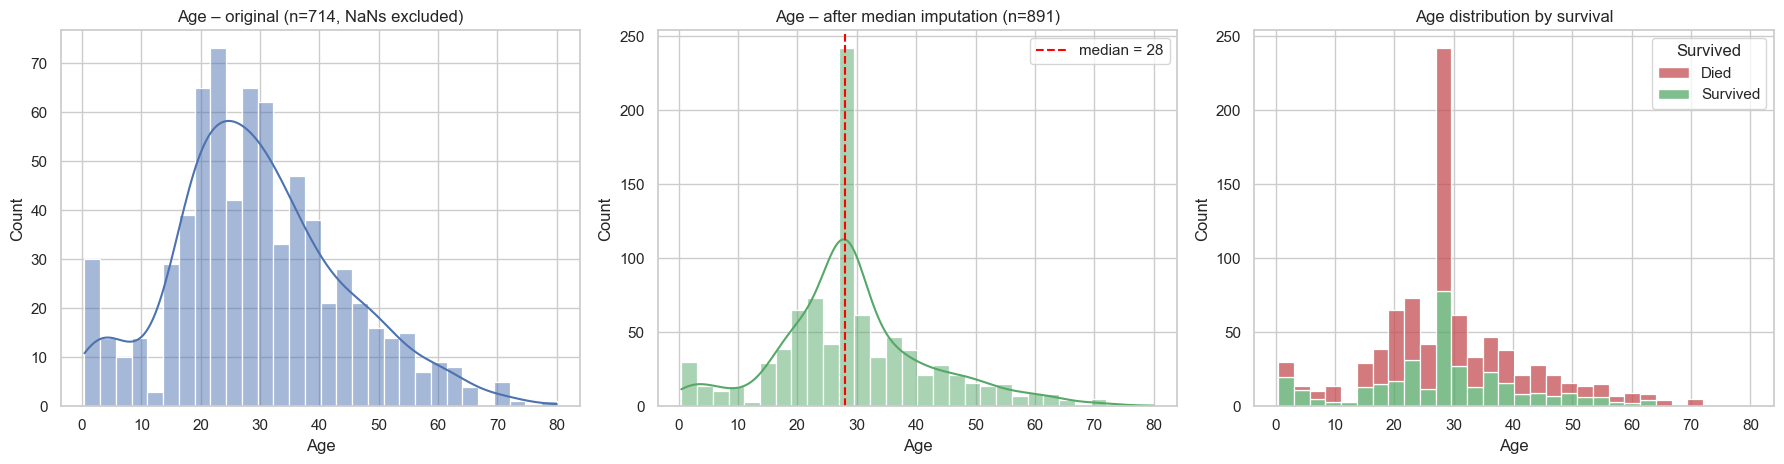

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

sns.histplot(raw['Age'].dropna(), bins=30, kde=True, color="#4C72B0", ax=ax[0])
ax[0].set_title(f"Age – original (n={raw['Age'].notnull().sum()}, NaNs excluded)")

sns.histplot(clean['Age'], bins=30, kde=True, color="#55A868", ax=ax[1])
ax[1].axvline(clean['Age'].median(), color='red', ls='--', label=f"median = {clean['Age'].median():.0f}")
ax[1].set_title(f"Age – after median imputation (n={len(clean)})")
ax[1].legend()

sns.histplot(data=clean, x='Age', hue=clean['Survived'].map({0: 'Died', 1: 'Survived'}),
             bins=30, multiple='stack', palette=['#C44E52', '#55A868'], ax=ax[2])
ax[2].set_title("Age distribution by survival")

plt.tight_layout()
plt.savefig("age_distribution.png", dpi=150)
plt.show()

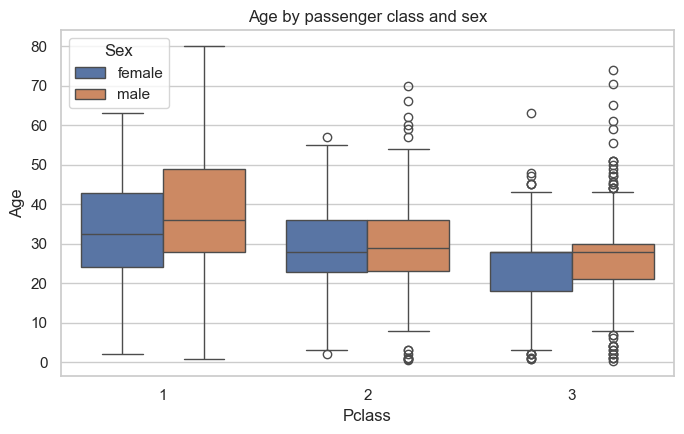

In [16]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=clean, x='Pclass', y='Age', hue='Sex')
plt.title("Age by passenger class and sex")
plt.tight_layout()
plt.savefig("age_boxplot.png", dpi=150)
plt.show()

**Insights**
- The imputed histogram has a spike at the median – the cost of imputation. The overall shape is otherwise preserved.
- Children (young ages) show a visibly higher survival share than most adult groups.
- Age differs by class (first class is older), so class-wise imputation is a reasonable future improvement.

### Step 5 – Export cleaned dataset

In [17]:
final_cols = ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Sex_encoded', 'Age',
              'Age_was_missing', 'SibSp', 'Parch', 'Ticket', 'Fare', 'HasCabin',
              'Embarked'] + emb_cols
clean_out = clean[final_cols]
clean_out.to_csv("titanic_cleaned.csv", index=False)

check = pd.read_csv("titanic_cleaned.csv")
print("Saved titanic_cleaned.csv ->", check.shape)
print("Total missing values:", check.isnull().sum().sum())
check.head()

Saved titanic_cleaned.csv -> (891, 17)
Total missing values: 0


,PassengerId,Survived,Pclass,Name,Sex,Sex_encoded,Age,Age_was_missing,SibSp,Parch,Ticket,Fare,HasCabin,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",male,1,22.0,0,1,0,A/5 21171,7.2500,0,S,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,0,38.0,0,1,0,PC 17599,71.2833,1,C,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,0,26.0,0,0,0,STON/O2. 3101282,7.9250,0,S,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,0,35.0,0,1,0,113803,53.1000,1,S,0,0,1
4,5,0,3,"Allen, Mr. William Henry",male,1,35.0,0,0,0,373450,8.0500,0,S,0,0,1


## Bonus – Scaling and Train/Test split
Split **first**, then fit the scaler on the training set only, to avoid data leakage.

In [18]:
features = ['Pclass', 'Sex_encoded', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin'] + emb_cols
X, y = clean_out[features], clean_out['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
num = ['Age', 'Fare']
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num] = scaler.fit_transform(X_train[num])
X_test_s[num] = scaler.transform(X_test[num])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))
print("Scaled train Age mean/std:", round(X_train_s['Age'].mean(), 3), "/", round(X_train_s['Age'].std(), 3))

Train: (712, 10) | Test: (179, 10)
Survival rate train/test: 0.383 / 0.385
Scaled train Age mean/std: 0.0 / 1.001


## Summary
- Loaded and profiled the Titanic data (891 rows × 12 columns).
- Imputed `Age` (median) and `Embarked` (mode), dropped `Cabin` while keeping a `HasCabin` flag.
- Encoded `Sex` (LabelEncoder) and `Embarked` (OneHotEncoder).
- Visualised age distribution before/after imputation and by survival.
- Exported `titanic_cleaned.csv` with zero missing values; created a leak-free scaled train/test split.